In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import matplotlib.colors as mcolors
import argparse
from pathlib import Path
import numpy as np
import sys
import os
import json

In [2]:
import matplotlib
import seaborn as sns
from types import SimpleNamespace

In [3]:
store_plots = True

In [4]:
hw_file = "../hardware.json"
predir = "prod"

In [5]:
sns.set(style="whitegrid")

matplotlib.rcParams.update(
{
"pgf.preamble": (
r"\usepackage{amsmath} \usepackage{amsfonts} \newcommand{\Var}{\operatorname{\mathds{V}!ar}}"
),
"pgf.texsystem": "pdflatex",
"font.family": "serif",
"text.usetex": True,
"pgf.rcfonts": True,
"axes.titleweight": "bold", # Make titles bold
"axes.titlesize": 16, # Increase title size
"axes.labelsize": 16, # Increase label size
"xtick.labelsize": 14, # Increase x-tick label size
"ytick.labelsize": 14, # Increase y-tick label size
"legend.fontsize": 12, # Increase legend font size
}
)

matplotlib.rcParams["text.latex.preamble"] = (
r"\usepackage{amsmath} \usepackage{amsfonts} \newcommand{\Var}{\operatorname{\mathds{V}!ar}}"
)

plt.rcParams.update(matplotlib.rcParams)

In [6]:
# returns Flops in unit that freq is given in
def compute_PP(cores, freq, Vsize, floatsize, ILP_fac, FMA_fac, nodes=1):
    return cores * freq * (Vsize / floatsize) * ILP_fac * FMA_fac * nodes

def compute_PP_vs_n(data):
    # possible FLOPs over n
    PP_vs_n = np.zeros(len(data["qubits"]), dtype=np.float64)
    for idx, n in enumerate(data["qubits"]):
        PP_vs_n[idx] = compute_PP(cores=data["cores"][idx], 
                            freq=data["freq"][idx], 
                            Vsize=data["HW"]["max_Vsize"], 
                            floatsize=8, 
                            ILP_fac=data["HW"]["ILP_factor_FMA"],
                            FMA_fac=2,
                            nodes=data["num_ranks"][idx])
    return PP_vs_n

def lighten(color, amount=0.5):
    r, g, b = mcolors.to_rgb(color)
    return (
        r + (1 - r) * amount,
        g + (1 - g) * amount,
        b + (1 - b) * amount,
    )

def compute_est_rel_err(est_moments, z_sigma):
    corr_est_rel_err = ((est_moments > 0) & (est_moments - z_sigma > 0))
    corr_est_rel_err = corr_est_rel_err | ((est_moments < 0) & (est_moments + z_sigma < 0))

    est_rel_err = z_sigma / np.abs( est_moments - np.sign(est_moments) * z_sigma )
    est_rel_err[~corr_est_rel_err] = np.inf

    return est_rel_err

def load_data(args, data_dir):
    # read in data_dir/*.npz
    data = {}
    qubits = []
    for npz_file in sorted(Path(data_dir).glob("*.npz")):
        tmp = dict(np.load(npz_file))
        for key in tmp:
            if type(tmp[key]) == np.ndarray and tmp[key].shape == (1,):
                tmp[key] = tmp[key][0]
        assert tmp["num_qubits"] not in data, "Only one file per num_qubits allowed"
        data[tmp["num_qubits"]] = tmp
        qubits.append(tmp["num_qubits"])

    # assert same parameters
    for idx, num_qubits in enumerate(data):
        if idx == 0:
            order = data[num_qubits]["order"]
            PT = data[num_qubits]["PT"]
            var_offset = data[num_qubits]["var_offset"]
            num_meas = data[num_qubits]["num_meas"]
            num_runs = data[num_qubits]["num_runs"]
            num_data_points = data[num_qubits]["num_data_points"]
        with open(f"{data_dir}/frequencies", "r") as f:
            lines = f.read().splitlines()
        if lines[idx + 1] != '':
            data[num_qubits]["freq"] = float(lines[idx + 1])            
        else:
            data[num_qubits]["freq"] = 0            
        # assert order == data[num_qubits]["order"]
        # assert var_offset == data[num_qubits]["var_offset"]
        # assert PT == data[num_qubits]["PT"]
        # assert num_meas == data[num_qubits]["num_meas"]
        # assert num_runs == data[num_qubits]["num_runs"]
        # assert num_data_points == data[num_qubits]["num_data_points"]
    min_qb = int(qubits[0])
    PT = bool(data[min_qb]["PT"])
    var_offset = int(data[min_qb]["var_offset"])
    num_meas = int(data[min_qb]["num_meas"])
    num_runs = int(data[min_qb]["num_runs"])       
    num_data_points = int(data[min_qb]["num_data_points"])       

    return data, np.array(qubits, dtype=int), np.arange(2, order + 1, dtype=int), PT, var_offset, num_meas, num_runs, num_data_points


def extract_data(args, in_data, qubits, orders, PT, var_offset, num_meas, num_runs, num_data_points, julia=False, compute_DICI=True):
    assert type(PT) == bool
    assert type(var_offset) == int
    assert type(num_meas) == int
    assert type(num_runs) == int
    assert type(num_data_points) == int

    len_qubits = len(qubits)
    len_orders = len(orders)

    data = {
        "qubits": qubits,
        "orders": orders,
        "PT": PT,
        "var_offset": var_offset,
        "num_meas": num_meas,
        "num_runs": num_runs,
        "num_data_points": num_data_points,
    }

    if julia:
        data["num_batches"] = in_data[2]["num_batches"]

    data["running"] = True

    # shape = (len_qubits, 1)
    data["runtimes"] = np.zeros(len_qubits, dtype=float)
    data["runtimesDSC"] = np.zeros(len_qubits, dtype=float)
    data["runtimesDSC_all"] = np.zeros([len_qubits, num_runs], dtype=float)
    data["num_threads"] = np.zeros(len_qubits, dtype=int)
    data["num_ranks"] = np.zeros(len_qubits, dtype=int)
    data["vector_width"] = np.zeros(len_qubits, dtype=int)
    data["rmMB"] = np.zeros(len_qubits, dtype=float)
    data["rsptMB"] = np.zeros(len_qubits, dtype=float)
    data["rfMF"] = np.zeros(len_qubits, dtype=float)
    data["rmtMB"] = np.zeros(len_qubits, dtype=float)
    data["freq"] = np.zeros(len_qubits, dtype=float)

    # shape = (len_qubits, len_orders)
    data["moments"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["est_moments"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["ERR"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["ERR_max"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["RE"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["RE_max"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["CI"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["CIOE"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["CIOE_min"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["ERE"] = np.zeros([len_qubits, len_orders], dtype=float)
    data["ERE_max"] = np.zeros([len_qubits, len_orders], dtype=float)

    # shape = (len_qubits, len_orders, num_runs)
    data["DICI"] = np.zeros([len_qubits, len_orders, num_runs], dtype=float)

    # shape = (len_qubits, len_orders, num_data_points)
    data["inter_tidx"] = np.zeros([len_qubits, num_data_points], dtype=int)
    data["est_inter_moments"] = np.zeros([len_qubits, len_orders, num_data_points], dtype=float)
    data["inter_CI"] = np.zeros([len_qubits, len_orders, num_data_points], dtype=float)
    data["inter_CIOE"] = np.zeros([len_qubits, len_orders, num_data_points], dtype=float)
    data["inter_ERR_in_sigma"] = np.zeros([len_qubits, len_orders, num_data_points], dtype=float)
    data["inter_RE"] = np.zeros([len_qubits, len_orders, num_data_points], dtype=float)
    data["inter_ERE"] = np.zeros([len_qubits, len_orders, num_data_points], dtype=float)
    
    for idx, n in enumerate(qubits):
        skip_o1 = 1 # we intentionally skip order 1 here
        moments = np.tile(in_data[n]["moments"][skip_o1:], num_runs).reshape(num_runs, len_orders)
        inter_moments = np.tile(in_data[n]["moments"][skip_o1:], num_data_points)
        inter_moments = np.tile(inter_moments, num_runs).reshape(num_runs, num_data_points, len_orders)
        est_moments = in_data[n]["est_moments"].reshape(num_runs, len_orders + 1)
        if not julia:
            stderrs = in_data[n]["est_std_errs"].reshape(num_runs, len_orders + 1)[:, skip_o1:]
        else: 
            stderrs = np.zeros(len_orders)        

        if np.all(stderrs == 0):
            data["running"] = False

        if data["num_data_points"] > 0 and data["running"]:
            est_inter_moments = in_data[n]["est_inter_moments"].reshape(num_runs, num_data_points, len_orders + 1)[:, :, skip_o1:]
            inter_tidx = in_data[n]["inter_tidx"]
            inter_stderrs = in_data[n]["est_inter_std_errs"].reshape(num_runs, num_data_points, len_orders + 1)[:, :, skip_o1:]
            inter_z_sigma = args.CI_fac * inter_stderrs
            if not args.julia:
                est_inter_rel_err = compute_est_rel_err(est_inter_moments, inter_z_sigma)

        distances = moments - est_moments[:, skip_o1:]
        errs = np.abs(moments - est_moments[:, skip_o1:])
        errs[errs == 0] = np.nan
        rel_errs = errs/np.abs(moments)
        z_sigma = args.CI_fac * stderrs
        if not args.julia:
            est_rel_err = compute_est_rel_err(est_moments[:, skip_o1:], z_sigma)
        DSC_only_runtime = np.median(est_moments[:,0]) # nasty

        if data["num_data_points"] > 0 and data["running"]:
            inter_errs_signed = inter_moments - est_inter_moments
            inter_errs_signed[inter_errs_signed == 0] = np.nan
            inter_errs = np.abs(inter_errs_signed)
            inter_rel_errs = inter_errs/np.abs(inter_moments)

        data["runtimes"][idx] = in_data[n]["runtime"]
        data["runtimesDSC"][idx] = DSC_only_runtime
        data["runtimesDSC_all"][idx] = est_moments[:,0]
        data["num_threads"][idx] = in_data[n]["num_threads"]
        if not args.julia:
            data["num_ranks"][idx] = in_data[n]["num_ranks"]
        data["vector_width"][idx] = in_data[n]["vector_width"]
        data["rmMB"][idx] = in_data[n]["rmMB"] # required memory in MB
        data["rsptMB"][idx] = in_data[n]["rsptMB"] # required array data (wo cs data) in MB 
        data["rfMF"][idx] = in_data[n]["rfMF"] # performed flops
        data["rmtMB"][idx] = in_data[n]["rmtMB"] # idk
        data["freq"][idx] = in_data[n]["freq"] * 1000 # GHz

        data["moments"][idx] = in_data[n]["moments"][skip_o1:]
        data["est_moments"][idx] = np.median(est_moments[:, skip_o1:], axis=0)
        data["ERR"][idx] = np.median(errs, axis=0) # ERRor
        data["ERR_max"][idx] = np.max(errs, axis=0)
        data["RE"][idx] = np.median(rel_errs, axis=0) # Relative Error
        data["RE_max"][idx] = np.max(rel_errs, axis=0)

        data["CI"][idx] = np.median(z_sigma, axis=0) # Confidence Interval
        data["CIOE"][idx] = np.median(z_sigma / errs, axis=0) # Confidence Interval OverEstimation
        data["CIOE_min"][idx] = np.min(z_sigma / errs, axis=0)

        if not args.julia:
            data["ERE"][idx] = np.median(est_rel_err, axis=0) # Estimated Relative Error
            data["ERE_max"][idx] = np.max(est_rel_err, axis=0)

        if compute_DICI == True:
            data["DICI"][idx] = np.transpose(distances/(z_sigma)) # Distance In Confidence Interval (unit)

        if data["num_data_points"] > 0 and data["running"]: 
            data["inter_tidx"][idx] = np.copy(inter_tidx)
            data["est_inter_moments"][idx] = np.transpose(np.median(est_inter_moments, axis=0))
            data["inter_CI"][idx] = np.transpose(np.median(inter_z_sigma, axis=0))
            data["inter_CIOE"][idx] = np.transpose(np.median(inter_z_sigma/inter_errs, axis=0))
            data["inter_ERR_in_sigma"][idx] = np.transpose(np.mean(inter_errs / inter_stderrs, axis=0))
            data["inter_RE"][idx] = np.transpose(np.median(inter_rel_errs, axis=0))
            data["inter_ERE"][idx] = np.transpose(np.median(est_inter_rel_err, axis=0))

    if PT:
        data["transposes"] = [0] * len_qubits
        for idx, n in enumerate(qubits):
            data["transposes"][idx] = in_data[n]["transposes"]


    if not args.julia:
        # add hw data
        with open(args.hw_file) as f:
            data["HW"] = json.load(f)[args.hardware]    

        if np.all(data["freq"] == 0):
            for idx, n in enumerate(qubits):      
                data["freq"][idx] = data["HW"]["freq"]  

        # used cores
        cores = data["num_threads"].copy()
        cores[cores > data["HW"]["cores"]] = data["HW"]["cores"]        
        data["cores"] = cores

        # peak performance in MFLOPs
        PP = compute_PP(cores=data["HW"]["cores"], 
                                freq=data["freq"], 
                                Vsize=data["HW"]["max_Vsize"], 
                                floatsize=args.floatsize, 
                                ILP_fac=data["HW"]["ILP_factor_FMA"],
                                FMA_fac=2,
                                nodes=max(data["num_ranks"]))       

        # compute achieved performance for each n
        if data["running"] == True:
            kmax = data["orders"][-1]
            Ns = 2**np.array(data["qubits"])     
            AP = 14 * Ns * data["num_meas"] * kmax * data["qubits"] * Ns # total flops

            # flops for adding with row state, not considered here
            # AP += 6 * Ns * data["num_meas"] * kmax * Ns 

            AP = AP / 1e6 # Mflops
            AP = AP / data["runtimesDSC"] # MFLOPs  

            # memory/ cache usage
            x = np.array(data["rsptMB"]).copy()
            SMT = data["num_threads"] > data["HW"]["cores"]
            x[SMT] = x[SMT] * 2

            data["pk_per_core"] = x / (kmax + 2) * kmax
            data["xy_per_core"] = x / (kmax + 2) * 2  

        else:
            kmax = data["orders"][-1]
            Ns = 2**np.array(data["qubits"])     
            AP = 14 * Ns * data["num_meas"] * data["qubits"] * Ns \
                + 6 * Ns * data["num_meas"] * Ns # total flops
            AP = AP / 1e6 # Mflops
            AP = AP / data["runtimesDSC"] # MFLOPs
            
            # memory/ cache usage
            x = np.array(data["rsptMB"]).copy()
            SMT = data["num_threads"] > data["HW"]["cores"]
            x[SMT] = x[SMT] * 2

            data["pk_per_core"] = x / 2
            data["xy_per_core"] = x / 2

        data["total_mem"] = data["rmMB"].copy()
    
        data["AP"] = AP
        data["PP"] = PP           


    return data

In [7]:
def get_data(data_dir, out_dir, state, hardware, version, julia=0):

    args = SimpleNamespace()

    args.data_dir = data_dir
    args.out_dir = out_dir
    args.state = state
    args.CI_perc = 95
    args.CI_fac = 1.960
    args.hw_file = hw_file
    args.hardware = hardware
    args.tol = 1
    args.julia = julia
    args.version = version
    args.floatsize = 8 # B
    args.strict_tol = args.tol / 10

    in_data, qubits, orders, PT, var_offset, num_meas, num_runs, num_data_points = load_data(args, args.data_dir)
    data = extract_data(args, in_data, qubits, orders, PT, var_offset, num_meas, num_runs, num_data_points, julia=args.julia, compute_DICI=(args.version.startswith("running")))
    data["colors"] = [x for x in mcolors.TABLEAU_COLORS.keys()]
    data["markers"] = ["o", "v", "p", "*", "s", "X"]
    data["linestyles"] = ["-", ":", "-."]
    data["lw"] = 1

    return data

Unlabeled dots are from RandomMeas.jl. It uses a distinct dataset, thus results are expected to vary to some degree.


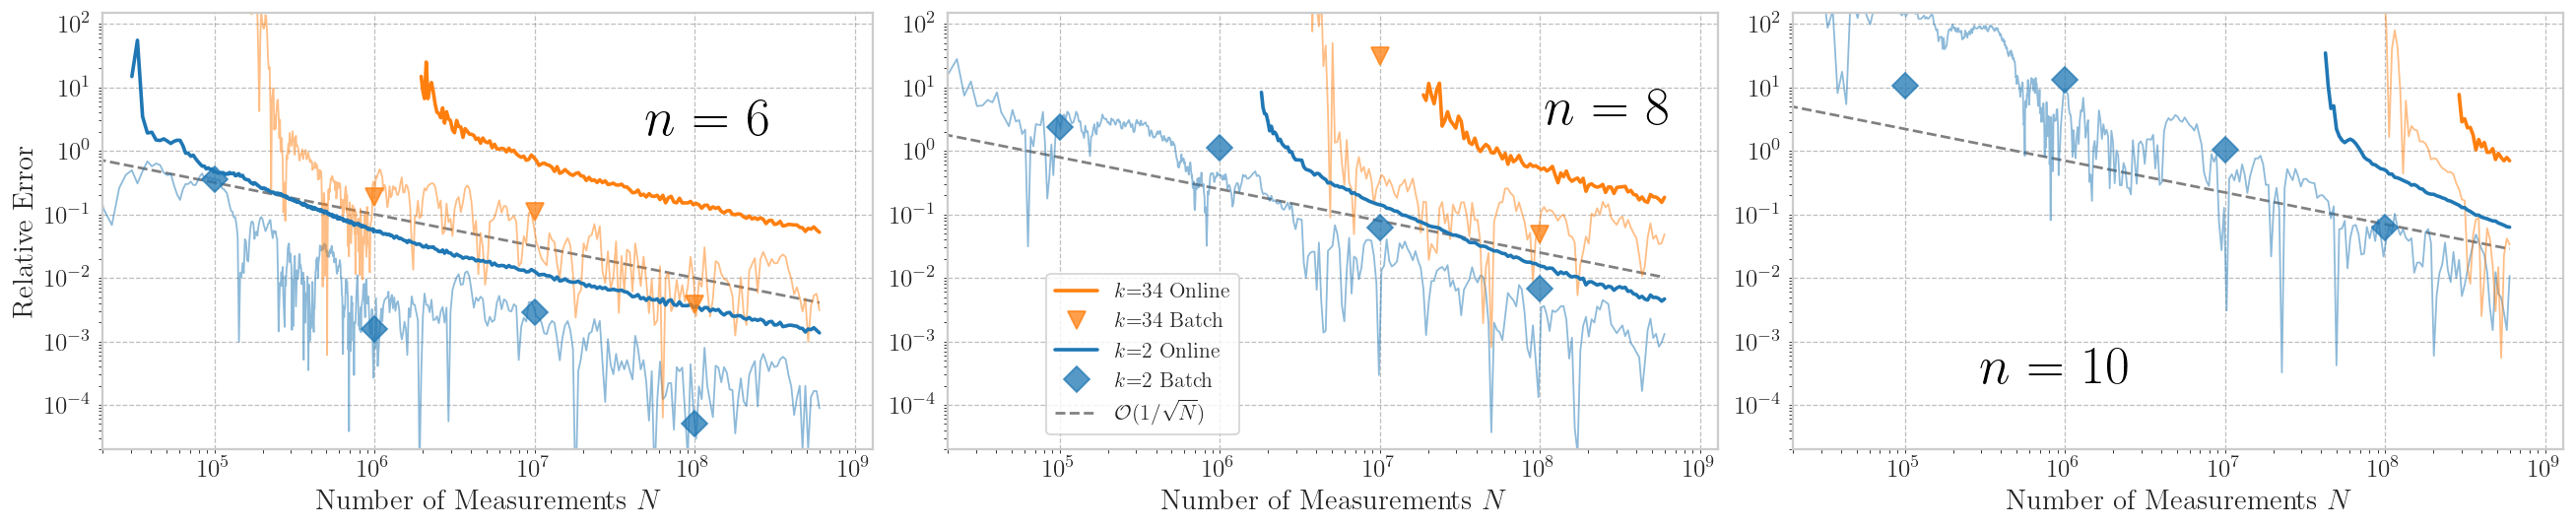

In [8]:
# Big Plot

ns = [6, 8, 10]
ms = [2, 34]
num_batches = [4, 5, 6, 7, 8]
facs = [100, 250, 700]

batched_dirs = f"{predir}/werner/vsc/batched_1e"

batches_jl = [6, 7, 8]
batched_dirs_jl = f"{predir}/werner/julia/batched_1e"

outdir = f"{predir}/plots"
outfile = f"{outdir}/werner"


fg, axes = plt.subplots(1, 3, figsize=(20, 4), dpi=130, layout="constrained")

for axidx, n in enumerate(ns):
    ax = axes[axidx]
        
    data_running = get_data(f"{predir}/werner/vsc/running", outdir, "werner", "7713", "running")

    datas_batched = []
    for x in num_batches:
        datas_batched.append(get_data(batched_dirs + str(x), outdir, "werner", "7713", "batched"))

    datas_batched_jl = []
    for x in batches_jl:
        datas_batched_jl.append(get_data(batched_dirs_jl + str(x), outdir, "werner", "7713", "batched", julia=1))

    ##################################################################

    nidx = np.where(data_running["qubits"] == n)[0][0]

    inter_tidx = []
    running_errs = []
    running_est_errs = []
    for order in ms:
        midx = order - 2
        inter_tidx.append(data_running["inter_tidx"][nidx] + midx)
        running_errs.append(data_running["inter_RE"][nidx, midx])
        running_est_errs.append(data_running["inter_ERE"][nidx, midx])

    # qubits = data_scalar["qubits"]
    # times_scalar = data_scalar["runtimesDSC"]
    # times_simd = data_simd["runtimesDSC"]


    ##################################################################

    # fg, ax = plt.subplots(layout="constrained", dpi=130)

    colors = [x for x in mcolors.TABLEAU_COLORS.keys()]
    markers = ["D", "v", "p", "*", "s", "X"]

    # -------------------- RUNNING -------------------- #
    fac = facs[axidx]
    ax.loglog(inter_tidx[0], fac/(inter_tidx[0])**(1/2), linestyle="--", c="grey", label="$\mathcal{O}(1/\sqrt{N})$")
    for idx, order in enumerate(ms):
        c = colors[idx%len(colors)]
        marker = None    
        ax.loglog(inter_tidx[idx], running_errs[idx], lw=1, c=c, alpha=0.5)    
    for idx, order in enumerate(ms):
        c = colors[idx%len(colors)]
        marker = None    
        infs = np.where(np.isinf(running_est_errs[idx]))[0]
        if len(infs > 0):
            mask = np.arange(len(running_est_errs[idx])) > np.where(np.isinf(running_est_errs[idx]))[0][-1]
        else:
            mask = np.arange(len(running_est_errs[idx]))  
        if axidx == 0:
            ax.loglog(inter_tidx[idx][mask], running_est_errs[idx][mask], lw=2, c=c, marker=marker, label=f"$k$={order} Online")       
        else:
            ax.loglog(inter_tidx[idx][mask], running_est_errs[idx][mask], lw=2, c=c, marker=marker)         

    # -------------------- BATCHED -------------------- #
    num_measss = []
    REs = np.zeros([len(ms), len(datas_batched)])
    for didx, data_batched in enumerate(datas_batched):
        num_measss.append(data_batched["num_meas"])
        for idx, order in enumerate(ms):
            midx = order - 2
            REs[idx, didx] = data_batched["RE"][nidx, midx]
    for idx, order in enumerate(ms):
        midx = order - 2
        c = colors[idx%len(colors)]
        marker = markers[idx%len(markers)]     
        if axidx == 0:
            ax.loglog(num_measss, REs[idx], linestyle="none", c=c, marker=marker, ms=10, alpha=0.75, label=f"$k$={order} Batch")       
        else:
            ax.loglog(num_measss, REs[idx], linestyle="none", c=c, marker=marker, ms=10, alpha=0.75)       

    # -------------------- JULIA -------------------- #
    # num_measss = [int(10**6), int(10**7), int(10**8)]
    # REs = np.zeros([len(ms), len(datas_batched_jl)])
    # for didx, data_batched in enumerate(datas_batched_jl):
    #     for idx, order in enumerate(ms):
    #         midx = order - 2
    #         REs[idx, didx] = data_batched["RE"][nidx, midx]
    # for idx, order in enumerate(ms):
    #     midx = order - 2
    #     c = colors[(idx+3)%len(colors)]
    #     marker = markers[(idx+3)%len(markers)]     
    #     if axidx == 0:
    #         ax.loglog(num_measss, REs[idx], linestyle="none", c=c, marker=marker, ms=10, alpha=0.75, label=f"$k$={order} Julia")       
    #     else:
    #         ax.loglog(num_measss, REs[idx], linestyle="none", c=c, marker=marker, ms=10, alpha=0.75)      


    ax.set_xlabel(r"Number of Measurements $N$")
    ax.set_ylabel("Relative Error")

    ax.grid(which="major", linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
    ax.grid(which="minor", visible=False)

    ax.set_ylim(2e-5, 1.5e2)      
    ax.set_xlim(2e4, 1.3e9)      

    ax.tick_params(
        axis="both",
        which="minor",
        bottom=True,
        top=False,
        left=True,
        right=False,
        length=2.4,
        width=0.5,
    )

    ax.tick_params(
        axis="both",
        which="major",
        bottom=True,
        top=False,
        left=True,
        right=False,
        length=2.4,
        width=0.5,
    )

    if axidx != 0:
        ax.set_ylabel('')        # hide the label

handles, labels = axes[0].get_legend_handles_labels()
handles = [handles[2], handles[4], handles[1], handles[3], handles[0]]
labels = [labels[2], labels[4], labels[1], labels[3], labels[0]]
fg.legend(handles, labels, ncol=1, fontsize=12, markerscale=1.0, handlelength=2.0, bbox_to_anchor=(0.485, 0.5))


fg.text(
    0.249, 0.75,
    "$n$ = 6",
    color="black",
    fontsize=30,
    fontweight="heavy"
)

fg.text(
    0.6, 0.77,
    "$n$ = 8",
    color="black",
    fontsize=30,
    fontweight="heavy"
)

fg.text(
    0.77, 0.265,
    "$n$ = 10",
    color="black",
    fontsize=30,
    fontweight="heavy"
)

print("Unlabeled dots are from RandomMeas.jl. It uses a distinct dataset, thus results are expected to vary to some degree.")

if store_plots:
    # fg.savefig(f"{outfile}.png")
    fg.savefig(f"{outfile}.pdf", bbox_inches="tight")
plt.show()

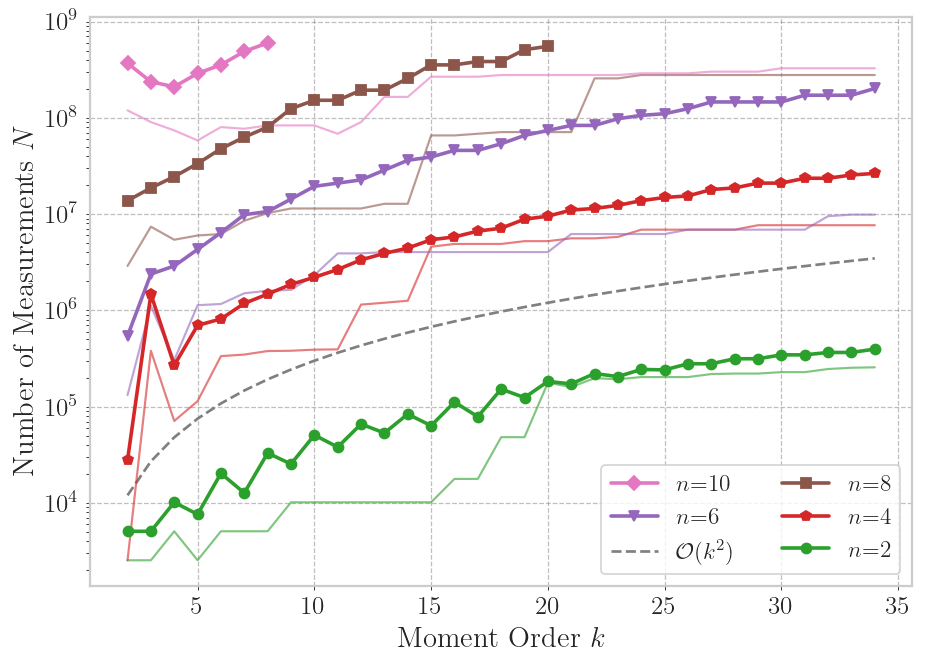

In [9]:
# convergence analysis

tol = 0.1

outdir = f"{predir}/plots"
outfile = f"{outdir}/werner_convergence"


##################################################################

data = get_data(f"{predir}/werner/vsc/running", outdir, "werner", "7713", "running")

##################################################################

qubits = data["qubits"]
orders = data["orders"]
conv_T = np.zeros([len(data["qubits"]), len(orders)], dtype=float)
est_conv_T = np.zeros([len(data["qubits"]), len(orders)], dtype=float)

for nidx, n in enumerate(qubits):
    for midx, m in enumerate(orders):
        running_est_errs = data["inter_ERE"][nidx, midx]
        valid = np.maximum.accumulate(running_est_errs[::-1])[::-1] < tol
        if valid.any():
            idx = np.argmax(valid)
            est_conv_T[nidx, midx] = (data["inter_tidx"][nidx] + midx)[idx]
        else:
            est_conv_T[nidx, midx] = np.nan        
        running_errs = data["inter_RE"][nidx, midx]
        valid = np.maximum.accumulate(running_errs[::-1])[::-1] < tol
        if valid.any():
            idx = np.argmax(valid)
            conv_T[nidx, midx] = (data["inter_tidx"][nidx] + midx)[idx]
        else:
            conv_T[nidx, midx] = np.nan               

##################################################################

fg, ax = plt.subplots(layout="constrained", dpi=130, figsize=(7, 5))

colors = [x for x in mcolors.TABLEAU_COLORS.keys()]
colors = colors[2:]
markers = ["o", "p", "v", "s", "D"]

ax.semilogy(orders, 3e3*orders**2, linestyle="--", c="grey", label="$\mathcal{O}(k^2)$")

for idx, n in enumerate(qubits):
    c = colors[idx%len(colors)]
    ax.semilogy(orders, conv_T[idx], lw=1.2, c=c, alpha=0.6)    
for idx, n in enumerate(qubits):
    c = colors[(len(qubits) - 1 - idx)%len(colors)]
    marker = markers[(len(qubits) - 1 - idx)%len(markers)]
    ax.semilogy(orders, est_conv_T[len(qubits) - 1 - idx], marker=marker, markersize=5.5, lw=2, c=c, label=f"$n$={qubits[len(qubits) - 1 - idx]}")    


ax.set_xlabel(r"Moment Order $k$")
ax.set_ylabel("Number of Measurements $N$")

handles, labels = ax.get_legend_handles_labels()
handles = [handles[1], handles[3], handles[0], handles[2], handles[4], handles[5]]
labels = [labels[1], labels[3], labels[0], labels[2], labels[4], labels[5]]
ax.legend(handles, labels, ncol=2, fontsize=13, markerscale=1, handlelength=2.0)
ax.grid(which="major", linestyle="--", linewidth=0.7, color="gray", alpha=0.5, label=f"n={n}")
ax.grid(which="minor", visible=False)

ax.tick_params(
    axis="both",
    which="minor",
    top=False,
    left=True,
    right=False,
    length=2.4,
    width=0.5,
)

ax.tick_params(
    axis="both",
    which="major",
    bottom=True,
    top=False,
    left=True,
    right=False,
    length=2.4,
    width=0.5,
)

if store_plots:
    # fg.savefig(f"{outfile}.png")
    fg.savefig(f"{outfile}_est.pdf", bbox_inches="tight")
plt.show()

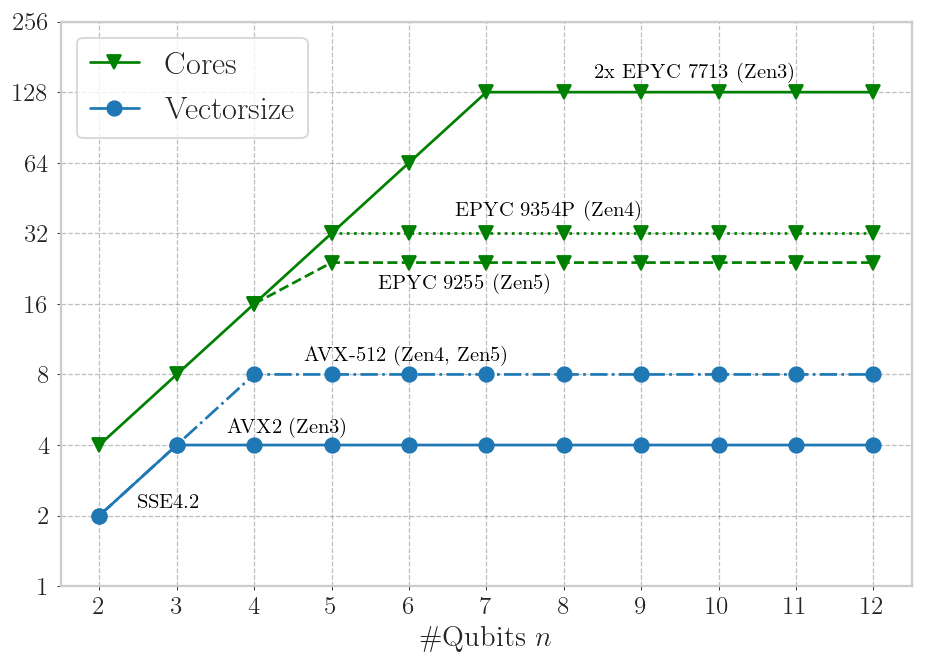

In [10]:
# Parallel specs

outdir = f"{predir}/plots"
outfile = f"{outdir}/par_specs"

##################################################################

data_running = get_data(f"{predir}/par_spec_template", outdir, "werner", "7713", "running")

##################################################################

qubits = np.array(list(data_running["qubits"]) + [11, 12], dtype=int)

data_running["cores"] = np.array(list(data_running["cores"]) + [128, 128])

manual_cores_zen4 = np.array([32]*len(qubits))
manual_cores_zen5 = np.array([24]*len(qubits))

data_running["num_threads"][-1] = data_running["num_threads"][-1]/2
data_running["num_threads"] = np.array(list(data_running["num_threads"]) + [128, 128])

manual_threads_batched = data_running["num_threads"].copy()
manual_threads_batched[6:] = manual_threads_batched[6:] * 2

data_running["vector_width"] =  np.array(list(data_running["vector_width"]) + [32, 32])/8

manual_AVX512 = data_running["vector_width"].copy()
manual_AVX512[2:] = manual_AVX512[2:] * 2

data_running["num_ranks"][-1] = data_running["num_ranks"][-1] * 2
x = data_running["num_ranks"][-1]
data_running["num_ranks"] = np.array(list(data_running["num_ranks"]) + [2*x, 4*x])


manual_num_ranks_batched = np.ones(len(qubits))



##################################################################

fg, ax = plt.subplots(layout="constrained", dpi=130, figsize=(7, 5))

colors = [x for x in mcolors.TABLEAU_COLORS.keys()]
colors[1] = "green"
markers = ["o", "v", "p", "D", "s", "X"]

markersize=8
# ax.semilogy(qubits[:], data_running["num_threads"][:], c=colors[2], marker="s", label="\#Threads", markersize=markersize)
# ax.semilogy(qubits[:], manual_threads_batched[:], c=colors[2], marker="s", linestyle="dashed", markersize=markersize)
ax.semilogy(qubits[:], data_running["cores"][:], c=colors[1], marker="v", label="Cores", markersize=markersize)
ax.semilogy(qubits[3:], manual_cores_zen4[3:], linestyle="dotted", c=colors[1], marker="v", markersize=markersize)
ax.semilogy([4] + list(qubits[3:]), [16] + list(manual_cores_zen5[3:]), linestyle="dashed", c=colors[1], marker="v", markersize=markersize)
ax.semilogy(qubits[:], data_running["vector_width"][:], c=colors[0], marker="o", label="Vectorsize", markersize=markersize)
ax.semilogy(qubits[:], manual_AVX512[:], c=colors[0], marker="o", linestyle="dashdot", markersize=markersize)
# ax.semilogy(qubits[:], data_running["num_ranks"][:], c=colors[3], marker="D", label="\#Nodes", markersize=markersize)
# ax.semilogy(qubits[:], manual_num_ranks_batched[:], c=colors[3], marker="D", linestyle="dashed", markersize=markersize)

ax.set_xlabel("\#Qubits $n$")
# ax.set_ylabel("\#cores/ \#threads/ \#nodes/ Vectorsize")

ax.set_xticks(list(np.arange(2, 13)))
ax.set_yticks([1, 2, 4, 8, 16, 32, 64, 128, 256])
ax.yaxis.set_major_formatter(ticker.ScalarFormatter())

ax.legend(ncol=1, fontsize=18, markerscale=1.0, handlelength=1.5)
ax.grid(which="major", linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.grid(which="minor", visible=False)     

ax.tick_params(
    axis="both",
    which="minor",
    bottom=False,
    top=False,
    left=False,
    right=False,
    length=2.4,
    width=0.5,
)

ax.tick_params(
    axis="both",
    which="major",
    bottom=True,
    top=False,
    left=True,
    right=False,
    length=2.4,
    width=0.5,
)

ax.text(
    2.5, 2.15,
    "SSE4.2",
    color="black",
    fontsize=11.5
)

ax.text(
    3.65, 4.5,
    "AVX2 (Zen3)",
    color="black",
    fontsize=11.5
)

ax.text(
    4.65, 9.2,
    "AVX-512 (Zen4, Zen5)",
    color="black",
    fontsize=11.5
)

ax.text(
    5.6, 18.5,
    "EPYC 9255 (Zen5)",
    color="black",
    fontsize=11.5
)

ax.text(
    6.6, 38,
    "EPYC 9354P (Zen4)",
    color="black",
    fontsize=11.5
)

ax.text(
    8.4, 147,
    "2x EPYC 7713 (Zen3)",
    color="black",
    fontsize=11.5
)

# ax.set_xlim(None, 13)

if store_plots:
    # fg.savefig(f"{outfile}.png")
    fg.savefig(f"{outfile}.pdf", bbox_inches="tight")
plt.show()

num_meas = 600000000
order = 34


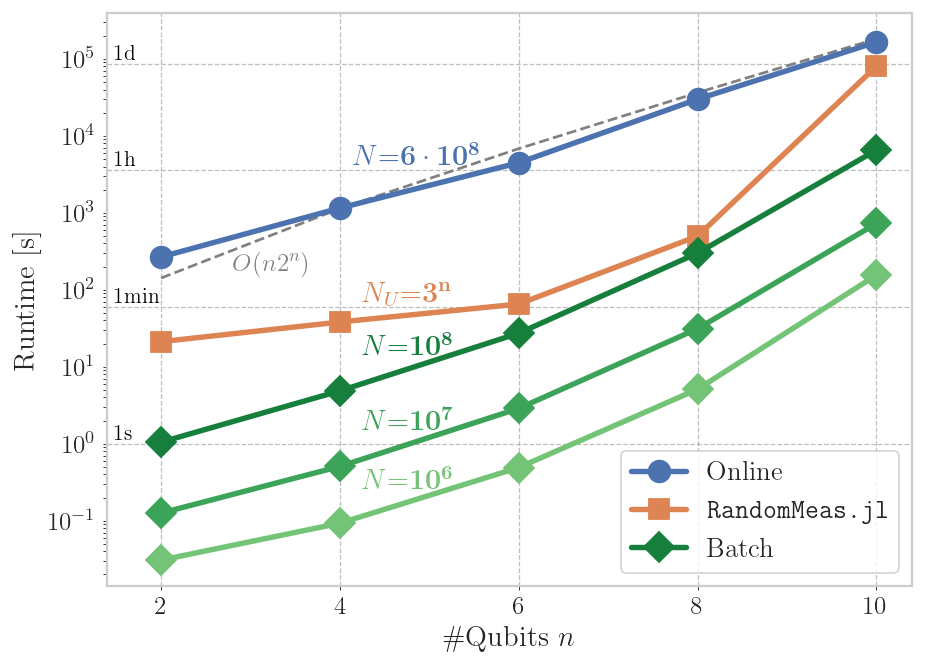

In [11]:
# Runtimes

outdir = f"{predir}/plots"
outfile = f"{outdir}/werner_runtimes"


batches_N_count = [6, 7, 8]
batched_dirs = f"{predir}/werner/vsc/batched_1e"

batches_jl = [7]
batched_dirs_jl = f"{predir}/werner/julia/batched_1e"

##################################################################

data_running = get_data(f"{predir}/werner/vsc/running", outdir, "werner", "7713", "running")

datas_batched = []
for x in batches_N_count:
    datas_batched.append(get_data(batched_dirs + str(x), outdir, "werner", "7713", "batched"))

datas_batched_jl = []
for x in batches_jl:
    datas_batched_jl.append(get_data(batched_dirs_jl + str(x), outdir, "werner", "7713", "batched", julia=1))

##################################################################

qubits = data_running["qubits"]
runtimes_running = data_running["runtimes"]

runtimes_batched = []
for i in range(len(batches_N_count)):
    runtimes_batched.append(datas_batched[i]["runtimes"])

runtimes_batched_jl = []
for i in range(len(batches_jl)):
    runtimes_batched_jl.append(datas_batched_jl[i]["runtimes"])

two_n_scaling = qubits*2**qubits / (qubits[0]*2**qubits[0]) * runtimes_running[0]/1.88
# four_n_scaling = qubits*4**qubits / two_n_scaling[2]

##################################################################

fg, ax = plt.subplots(layout="constrained", dpi=130, figsize=(7, 5))

colors = [x for x in mcolors.TABLEAU_COLORS.keys()]
markers = ["o", "v", "p", "*", "s", "X"]

ax.axhline(y=1, linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.axhline(y=60, linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.axhline(y=60*60, linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.axhline(y=60*60*24, linestyle="--", linewidth=0.7, color="gray", alpha=0.5)

ax.semilogy(qubits, two_n_scaling, linestyle="--", c="grey")
# ax.semilogy(qubits[1:], (four_n_scaling*26)[1:], linestyle="--", c="black")
# ax.semilogy(qubits[:5], (two_n_scaling/40)[:5], linestyle="--", c="grey")

color_running = ax._get_lines.get_next_color()
ax.semilogy(qubits, runtimes_running, marker="o", c=color_running, label="Online", lw=3, markersize=12)

color_jl = ax._get_lines.get_next_color()
ax.semilogy(qubits, runtimes_batched_jl[0], marker="s", c=color_jl, label=r"\texttt{RandomMeas.jl}", lw=3, markersize=11.5)
# for i in range(1, len(batches_jl)):
#     ax.semilogy(qubits, runtimes_batched_jl[i], marker="s", lw=3, markersize=11.5)

cmap = plt.get_cmap("Greens")
batched_colors = cmap(np.linspace(0.5, 0.8, len(runtimes_batched)))

ax.semilogy(qubits, runtimes_batched[0], marker="D", c=batched_colors[0], lw=3, markersize=11.5)
for i in range(1, len(batches_N_count)):
    if i == len(batches_N_count) - 1:
        ax.semilogy(qubits, runtimes_batched[i], marker="D", c=batched_colors[i], label="Batch", lw=3, markersize=11.5)
    else:
        ax.semilogy(qubits, runtimes_batched[i], marker="D", c=batched_colors[i], lw=3, markersize=11.5)

ax.set_xlabel("\#Qubits $n$")
ax.set_ylabel("Runtime [s]")

ax.set_xlim(1.4, None)

ax.legend(ncol=1, fontsize=15, markerscale=1.0, handlelength=2.0)
ax.grid(which="major", linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.grid(axis="y", visible=False)
ax.grid(which="minor", visible=False)     

ax.tick_params(
    axis="both",
    which="minor",
    bottom=False,
    top=False,
    left=True,
    right=False,
    length=2.4,
    width=0.5,
)

ax.tick_params(
    axis="both",
    which="major",
    bottom=True,
    top=False,
    left=True,
    right=False,
    length=2.4,
    width=0.5,
)

ax.set_xticks(qubits)

ax.text(
    1.47, 1 * 1.125,
    "1s",
    color="black",
    fontsize=12
)

ax.text(
    1.47, 60 * 1.125,
    "1min",
    color="black",
    fontsize=12
)

ax.text(
    1.47, 60 * 60 * 1.125,
    "1h",
    color="black",
    fontsize=12
)

ax.text(
    1.47, 60 * 60 * 24 * 1.125,
    "1d",
    color="black",
    fontsize=12
)

ax.text(
    2.8, 175,
    "$O(n2^n)$",
    color="grey",
    fontsize=14
)

ax.text(
    4.15, 4200,
    "$N$=$\mathbf{6\cdot10^8}$",
    color=color_running,
    fontsize=16
)

ax.text(
    4.25, 70,
    "$N_U$=$\mathbf{3^n}$",
    color=color_jl,
    fontsize=16
)

ax.text(
    4.25, 14.5,
    "$N$=$\mathbf{10^8}$",
    color=batched_colors[2],
    fontsize=16
)

ax.text(
    4.25, 1.5,
    "$N$=$\mathbf{10^7}$",
    color=batched_colors[1],
    fontsize=16
)

ax.text(
    4.25, 0.26,
    "$N$=$\mathbf{10^6}$",
    color=batched_colors[0],
    fontsize=16
)



if store_plots:
    # fg.savefig(f"{outfile}.png")
    fg.savefig(f"{outfile}.pdf", bbox_inches="tight")
    
print(f"num_meas = {data_running['num_meas']}")
print(f"order = {data_running['orders'][-1]}")
plt.show()

In [12]:
print(runtimes_batched_jl[0] / runtimes_batched[0])
print(runtimes_batched_jl[0] / runtimes_batched[1])
print(runtimes_batched_jl[0] / runtimes_batched[2])

[689.65873675 411.11751533 133.22615971  97.58232319 515.83266303]
[168.96728779  75.13797994  22.725219    15.95588871 110.13158661]
[20.23496045  7.84355111  2.39554825  1.66138015 12.25993249]


2
4
6
8
10

2.2e+03
5.2e+02
1.3e+02
2.0e+01
3.6e+00
num_meas = 600000000
order = 34
#data points = 500


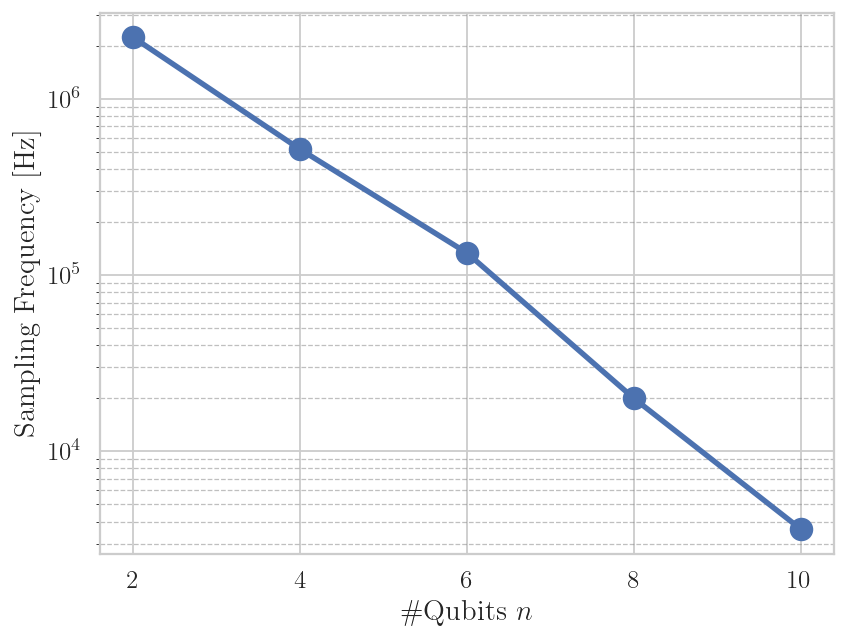

In [13]:
# sampling frequencies

outdir = f"{predir}/plots"
outfile = f"{outdir}/sampling_frequencies"

##################################################################

data = get_data(f"{predir}/werner/vsc/running", outdir, "werner", "7713", "running")

##################################################################

qubits = data["qubits"]
runtimes = data["runtimes"]
sampling_frequency = data["num_meas"]/runtimes

##################################################################

fg, ax = plt.subplots(layout="constrained", dpi=130)

colors = [x for x in mcolors.TABLEAU_COLORS.keys()]
markers = ["o", "v", "p", "*", "s", "X"]

ax.semilogy(qubits, sampling_frequency, marker="o", lw=3, markersize=12)

for x in qubits:
    print(f"{x}")
print()
for x in sampling_frequency:
    print(f"{x/1e3:.1e}")

ax.set_xlabel("\#Qubits $n$")
ax.set_ylabel("Sampling Frequency [Hz]")

# ax.legend(ncol=1, fontsize=15, markerscale=1.0, handlelength=2.0)
ax.grid(which="minor", linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
# ax.grid(which="minor", visible=False)     

ax.tick_params(
    axis="both",
    which="minor",
    bottom=False,
    top=False,
    left=True,
    right=False,
    length=2.4,
    width=0.5,
)


ax.set_xticks(qubits)

# if store_plots:
#     # fg.savefig(f"{outfile}.png")
#     fg.savefig(f"{outfile}.pdf", bbox_inches="tight")
    
print(f"num_meas = {data['num_meas']}")
print(f"order = {data['orders'][-1]}")
print(f"#data points = {data['num_data_points']}")
plt.show()

nodes = [1]:  num_meas =  100000, order = 34, qubits = [12], num_runs = 11
nodes = [2]:  num_meas =  100000, order = 34, qubits = [12], num_runs = 11
nodes = [4]:  num_meas =  100000, order = 34, qubits = [12], num_runs = 11
nodes = [8]:  num_meas =  100000, order = 34, qubits = [12], num_runs = 11
nodes = [16]:  num_meas =  100000, order = 34, qubits = [12], num_runs = 11


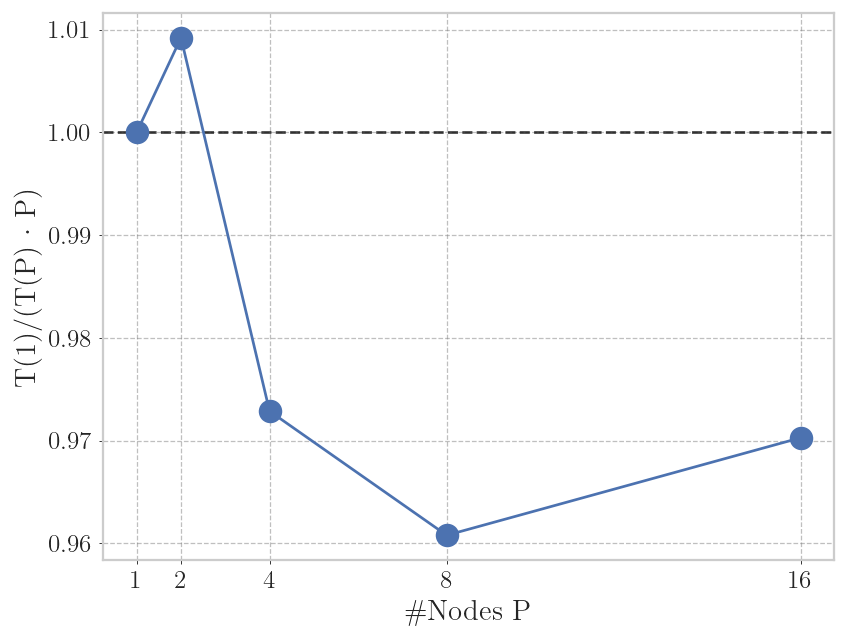

In [14]:
# Strong scaling efficiency

num_nodes = [1,2,4,8,16]

outdir = f"{predir}/plots"
outfile = f"{outdir}/strong_scaling"

##################################################################

datas = []
for idx, num_node in enumerate(num_nodes):
    datas.append(get_data(f"{predir}/rX/r{num_node}", outdir, "werner", "7713", "running"))
    assert datas[idx]["num_ranks"][0] == num_node

##################################################################

runtimes = []
for idx, num_node in enumerate(num_nodes):
    runtimes.append(datas[idx]["runtimes"])

strong_scal_eff = []
for idx, num_node in enumerate(num_nodes):
    strong_scal_eff.append(runtimes[0]/(runtimes[idx] * num_node))

##################################################################

fg, ax = plt.subplots(layout="constrained", dpi=130)

colors = [x for x in mcolors.TABLEAU_COLORS.keys()]
markers = ["o", "v", "p", "*", "s", "X"]

ax.axhline(y=1, linestyle="--", c="black", alpha=0.75)
ax.plot(num_nodes, strong_scal_eff , marker="o", markersize=12)

ax.set_xlabel("\#Nodes P")
ax.set_ylabel("T(1)/(T(P) $\cdot$ P)")

ax.grid(which="major", linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.grid(which="minor", visible=False)     

ax.tick_params(
    axis="both",
    which="major",
    bottom=True,
    top=False,
    left=True,
    right=False,
    length=2.4,
    width=0.5,
)

ax.set_xticks(num_nodes)

# if store_plots:
#     # fg.savefig(f"{outfile}.png")
#     fg.savefig(f"{outfile}.pdf", bbox_inches="tight")

for data in datas:
    print(f"nodes = {data['num_ranks']}:  num_meas =  {data['num_meas']}, order = {data['orders'][-1]}, qubits = {data['qubits']}, num_runs = {data['num_runs']}")
plt.show()

qubits = [2 3 4 5 6 7 8]:  num_meas =  10000000, order = 34, num_runs = 11
qubits = [ 9 10 11]:  num_meas =  50000, order = 34, num_runs = 11
qubits = [2 3 4 5 6 7 8]:  num_meas =  10000000, order = 34, num_runs = 11
qubits = [ 9 10 11]:  num_meas =  50000, order = 34, num_runs = 11


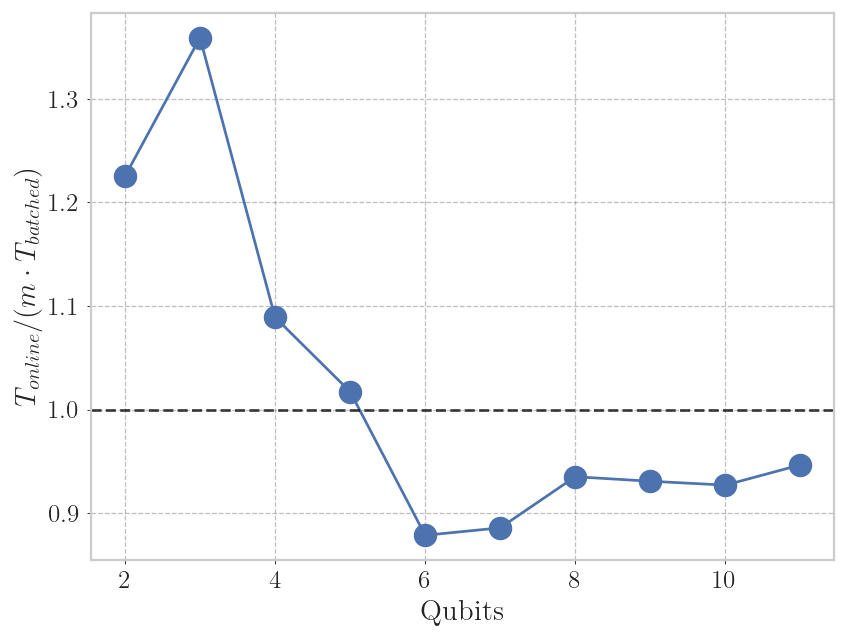

In [15]:
# running to batched

splits = [8, 11]

outdir = f"{predir}/plots"
outfile = f"{outdir}/running_to_batched"

##################################################################

data_running = []
for split in splits:
    data_running.append(get_data(f"{predir}/mm/vsc/simd/{split}", outdir, "werner", "7713", "running"))

data_batched = []
for split in splits:
    data_batched.append(get_data(f"{predir}/mm/vsc/batched/{split}", outdir, "werner", "7713", "batched"))

##################################################################

qubits = []
for data in data_running:
    qubits = qubits + list(data["qubits"])
qubits = np.array(qubits)

runtimes_running = []
for data in data_running:
    runtimes_running = runtimes_running + list(data["runtimesDSC_all"])
runtimes_running = np.array(runtimes_running)

runtimes_batched = []
for data in data_batched:
    runtimes_batched = runtimes_batched + list(data["runtimesDSC_all"])
runtimes_batched = np.array(runtimes_batched)

eff = np.median(runtimes_running/(data_running[0]["orders"][-1] * runtimes_batched), axis=1)

##################################################################

fg, ax = plt.subplots(layout="constrained", dpi=130)

colors = [x for x in mcolors.TABLEAU_COLORS.keys()]
markers = ["o", "v", "p", "*", "s", "X"]

ax.plot(qubits, eff, marker="o", markersize=12)

ax.axhline(y=1, linestyle="--", c="black", alpha=0.75)

ax.set_xlabel("Qubits")
ax.set_ylabel("$T_{online}/(m \cdot T_{batched})$")

ax.grid(which="major", linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.grid(which="minor", visible=False)     

ax.tick_params(
    axis="both",
    which="minor",
    bottom=False,
    top=False,
    left=False,
    right=False,
    length=2.4,
    width=0.5,
)

ax.tick_params(
    axis="both",
    which="major",
    bottom=True,
    top=False,
    left=True,
    right=False,
    length=2.4,
    width=0.5,
)

# if store_plots:
#     # fg.savefig(f"{outfile}.png")
#     fg.savefig(f"{outfile}.pdf", bbox_inches="tight")

for data in data_running:
    print(f"qubits = {data['qubits']}:  num_meas =  {data['num_meas']}, order = {data['orders'][-1]}, num_runs = {data['num_runs']}")
for data in data_batched:
    print(f"qubits = {data['qubits']}:  num_meas =  {data['num_meas']}, order = {data['orders'][-1]}, num_runs = {data['num_runs']}")    
plt.show()

/tmp/ipykernel_104777/1477150450.py:98: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fg.savefig(f"{outfile}.pdf", bbox_inches="tight")


nodes = [1]:  num_meas =  100000, order = 34, qubits = [12], num_runs = 11
nodes = [2]:  num_meas =  100000, order = 34, qubits = [12], num_runs = 11
nodes = [4]:  num_meas =  100000, order = 34, qubits = [12], num_runs = 11
nodes = [8]:  num_meas =  100000, order = 34, qubits = [12], num_runs = 11
nodes = [16]:  num_meas =  100000, order = 34, qubits = [12], num_runs = 11


/home/matthias/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


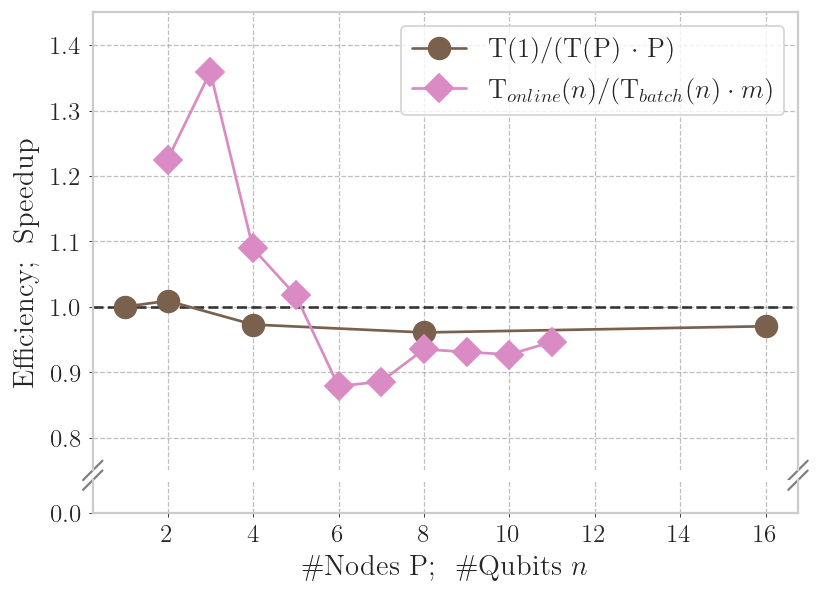

In [16]:
from brokenaxes import brokenaxes

# Strong scaling efficiency

num_nodes = [1,2,4,8,16]
splits = [8, 11]

outdir = f"{predir}/plots"
outfile = f"{outdir}/strong_scaling_and_running_to_batched"

##################################################################

datas = []
for idx, num_node in enumerate(num_nodes):
    datas.append(get_data(f"{predir}/rX/r{num_node}", outdir, "werner", "7713", "running"))
    assert datas[idx]["num_ranks"][0] == num_node


data_running = []
for split in splits:
    data_running.append(get_data(f"{predir}/mm/vsc/simd/{split}", outdir, "werner", "7713", "running"))

data_batched = []
for split in splits:
    data_batched.append(get_data(f"{predir}/mm/vsc/batched/{split}", outdir, "werner", "7713", "batched"))

##################################################################

runtimes = []
for idx, num_node in enumerate(num_nodes):
    runtimes.append(datas[idx]["runtimes"])

strong_scal_eff = []
for idx, num_node in enumerate(num_nodes):
    strong_scal_eff.append(runtimes[0]/(runtimes[idx] * num_node))


qubits = []
for data in data_running:
    qubits = qubits + list(data["qubits"])
qubits = np.array(qubits)

runtimes_running = []
for data in data_running:
    runtimes_running = runtimes_running + list(data["runtimesDSC_all"])
runtimes_running = np.array(runtimes_running)

runtimes_batched = []
for data in data_batched:
    runtimes_batched = runtimes_batched + list(data["runtimesDSC_all"])
runtimes_batched = np.array(runtimes_batched)

eff = np.median(runtimes_running/(data_running[0]["orders"][-1] * runtimes_batched), axis=1)

##################################################################

fg, ax = plt.subplots(layout="constrained", figsize=(7, 5))
colors = []
for i in range(10):
    colors.append(ax._get_lines.get_next_color())
plt.close()

fg = plt.figure(layout="constrained", dpi=130, figsize=(7, 5))

ax = brokenaxes(ylims=((0, 0.05), (0.75, 1.45)), hspace=0.04, despine=False, diag_color="grey")

markers = ["o", "v", "p", "*", "s", "X"]

ax.axhline(y=1, linestyle="--", c="black", alpha=0.75)
ax.plot(num_nodes, strong_scal_eff , marker="o", markersize=12, c=(0.48, 0.38, 0.30), label="T(1)/(T(P) $\cdot$ P)")
ax.plot(qubits, eff, marker="D", markersize=11, c=colors[6], label="T$_{online}(n)/($T$_{batch}(n) \cdot m)$")

ax.set_xlabel("\#Nodes P; \  \#Qubits $n$", labelpad=23)
ax.set_ylabel("Efficiency; \  Speedup")
# ax.set_ylabel("T(1)/(T(P) $\cdot$ P)")

ax.legend(ncol=1, fontsize=15, markerscale=1.0, handlelength=2.0)
ax.grid(which="major", linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.grid(which="minor", visible=False)     

# ax.set_ylim(0, None)

ax.tick_params(
    axis="both",
    which="major",
    bottom=True,
    top=False,
    left=True,
    right=False,
    length=2.4,
    width=0.5,
)

# ax.set_xticks(num_nodes)

if store_plots:
    # fg.savefig(f"{outfile}.png")
    fg.savefig(f"{outfile}.pdf", bbox_inches="tight")

for data in datas:
    print(f"nodes = {data['num_ranks']}:  num_meas =  {data['num_meas']}, order = {data['orders'][-1]}, qubits = {data['qubits']}, num_runs = {data['num_runs']}")
plt.show()

scalar, vsc, qubits = [2 3 4 5 6 7 8]:  num_meas =  10000000, order = 34, num_runs = 11
scalar, vsc, qubits = [ 9 10 11]:  num_meas =  50000, order = 34, num_runs = 11
scalar, vsc, qubits = [12]:  num_meas =  50000, order = 34, num_runs = 11
simd, vsc, qubits = [2 3 4 5 6 7 8]:  num_meas =  10000000, order = 34, num_runs = 11
simd, vsc, qubits = [ 9 10 11]:  num_meas =  50000, order = 34, num_runs = 11
simd, vsc, qubits = [12]:  num_meas =  50000, order = 34, num_runs = 11
scalar, hpcgpu2, qubits = [2 3 4 5 6 7 8]:  num_meas =  10000000, order = 34, num_runs = 11
scalar, hpcgpu2, qubits = [ 9 10 11]:  num_meas =  50000, order = 34, num_runs = 11
scalar, hpcgpu2, qubits = [12]:  num_meas =  50000, order = 34, num_runs = 11
simd, hpcgpu2, qubits = [2 3 4 5 6 7 8]:  num_meas =  10000000, order = 34, num_runs = 11
simd, hpcgpu2, qubits = [ 9 10 11]:  num_meas =  50000, order = 34, num_runs = 11
simd, hpcgpu2, qubits = [12]:  num_meas =  50000, order = 34, num_runs = 11
scalar, hpcgpu3, qub

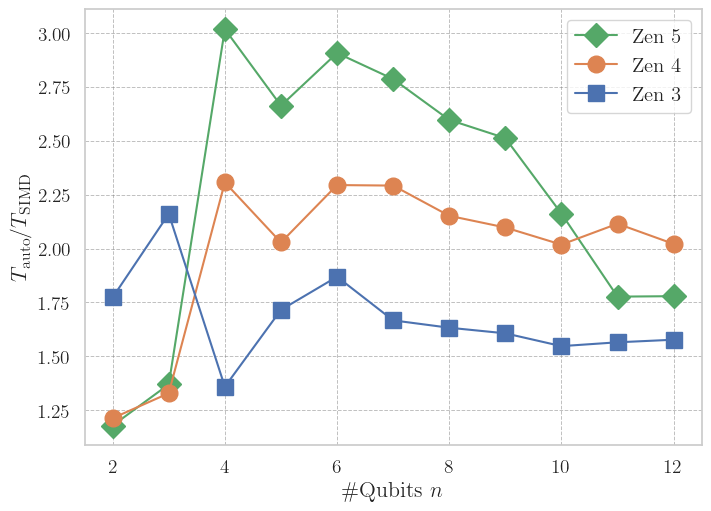

In [17]:
# SIMD Speedup

outdir = f"{predir}/plots"
outfile = f"{outdir}/simdSU"

splits = [8, 11, 12]
archs = [3, 4, 5] # zen3, zen4, zen5
names = {3: "vsc", 4 : "hpcgpu2", 5 : "hpcgpu3"}
hardwares = {3: "7713", 4 : "9354P", 5 : "9255"}


##################################################################

datas_scalar = {}
datas_simd = {}

for arch in archs:
    datas_scalar[arch] = []
    for split in splits:
        datas_scalar[arch].append(get_data(f"{predir}/mm/{names[arch]}/scalar/{split}", outdir, "werner", hardwares[arch], "running"))

    datas_simd[arch] = []
    for split in splits:
        datas_simd[arch].append(get_data(f"{predir}/mm/{names[arch]}/simd/{split}", outdir, "werner", hardwares[arch], "running"))

##################################################################

qubits = []
for data in datas_scalar[3]:
    qubits = qubits + list(data["qubits"])
qubits = np.array(qubits)

times_scalar = {}
times_simd = {}

for arch in archs:
    times_scalar[arch] = []
    for data in datas_scalar[arch]:
        times_scalar[arch] = times_scalar[arch] + list(data["runtimesDSC_all"])
    times_scalar[arch] = np.array(times_scalar[arch])

    times_simd[arch] = []
    for data in datas_simd[arch]:
        times_simd[arch] = times_simd[arch] + list(data["runtimesDSC_all"])
    times_simd[arch] = np.array(times_simd[arch])


SU3 = np.median(times_scalar[3]/times_simd[3], axis=1)
SU4 = np.median(times_scalar[4]/times_simd[4], axis=1)
SU5 = np.median(times_scalar[5]/times_simd[5], axis=1)

##################################################################

fg, ax = plt.subplots(layout="constrained", figsize=(7, 5))

colors = []
for i in range(10):
    colors.append(ax._get_lines.get_next_color())

ax.plot(qubits, SU5 , marker="D", c=colors[2], markersize=12, label="Zen 5")
ax.plot(qubits, SU4 , marker="o", c=colors[1], markersize=12, label="Zen 4")
ax.plot(qubits, SU3 , marker="s", c=colors[0], markersize=12, label="Zen 3")

ax.legend(ncol=1, fontsize=15, markerscale=1.0, handlelength=2.0)
ax.set_xlabel("\#Qubits $n$")
ax.set_ylabel("$T_{\mathrm{auto}}/T_{\mathrm{SIMD}}$")
ax.grid(which="major", linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.grid(which="minor", visible=False)

for arch in archs:
    for data in datas_scalar[arch]:
        print(f"scalar, {names[arch]}, qubits = {data['qubits']}:  num_meas =  {data['num_meas']}, order = {data['orders'][-1]}, num_runs = {data['num_runs']}")
    for data in datas_simd[arch]:
        print(f"simd, {names[arch]}, qubits = {data['qubits']}:  num_meas =  {data['num_meas']}, order = {data['orders'][-1]}, num_runs = {data['num_runs']}")

if store_plots:
    # fg.savefig(f"{outfile}.png")
    fg.savefig(f"{outfile}.pdf", bbox_inches="tight")
plt.show()

vsc, qubits = [2 3 4 5 6 7 8]:  num_meas =  10000000, order = 34, num_runs = 11
vsc, qubits = [ 9 10 11]:  num_meas =  50000, order = 34, num_runs = 11
vsc, qubits = [12]:  num_meas =  50000, order = 34, num_runs = 11
hpcgpu2, qubits = [2 3 4 5 6 7 8]:  num_meas =  10000000, order = 34, num_runs = 11
hpcgpu2, qubits = [ 9 10 11]:  num_meas =  50000, order = 34, num_runs = 11
hpcgpu2, qubits = [12]:  num_meas =  50000, order = 34, num_runs = 11
hpcgpu3, qubits = [2 3 4 5 6 7 8]:  num_meas =  10000000, order = 34, num_runs = 11
hpcgpu3, qubits = [ 9 10 11]:  num_meas =  50000, order = 34, num_runs = 11
hpcgpu3, qubits = [12]:  num_meas =  50000, order = 34, num_runs = 11


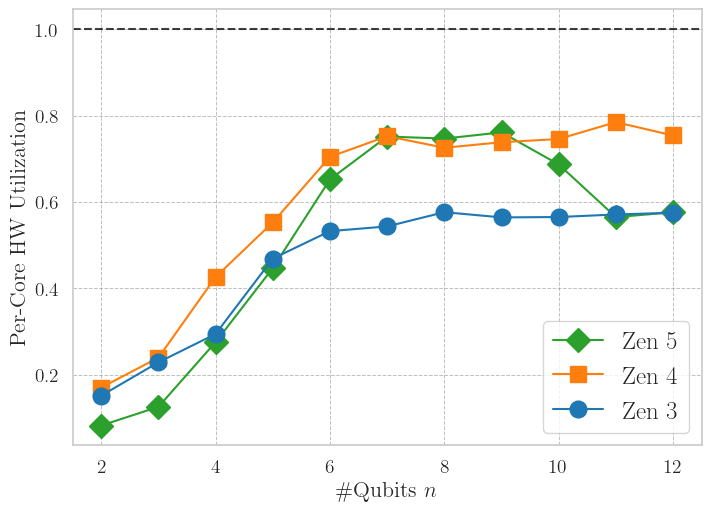

In [18]:
# throughput

outdir = f"{predir}/plots"
outfile = f"{outdir}/throughput"

splits = [8, 11, 12]

archs = [3, 4, 5] # zen3, zen4, zen5
names = {3: "vsc", 4 : "hpcgpu2", 5 : "hpcgpu3"}
hardwares = {3: "7713", 4 : "9354P", 5 : "9255"}

##################################################################

datas = {}

for arch in archs:
    datas[arch] = []
    for split in splits:
        datas[arch].append(get_data(f"{predir}/mm/{names[arch]}/simd/{split}", outdir, "werner", hardwares[arch], "running"))

##################################################################


qubits = []
for data in datas[3]:
    qubits = qubits + list(data["qubits"])
qubits = np.array(qubits)

utils = {}

for arch in archs:
    utils[arch] = []
    for data in datas[arch]:
        utils[arch] = utils[arch] + list(data["AP"]/compute_PP_vs_n(data))
    utils[arch] = np.array(utils[arch])


##################################################################

fg, ax = plt.subplots(layout="constrained", figsize=(7, 5))

colors = [x for x in mcolors.TABLEAU_COLORS.keys()]

ax.plot(qubits, utils[5], marker="D", label="Zen 5", c=colors[2], markersize=12)
ax.plot(qubits, utils[4], marker="s", label="Zen 4", c=colors[1], markersize=12)
ax.plot(qubits, utils[3], marker="o", label="Zen 3", c=colors[0], markersize=12)

# ax.plot(qubits, data_zen3["freq"]/data_zen3["HW"]["max_freq"], marker="v", label="Zen3 freq")
# ax.plot(qubits_45, data_zen4["freq"]/data_zen4["HW"]["max_freq"], marker="v", label="Zen4 freq")
# ax.plot(qubits, data_zen5["freq"]/data_zen5["HW"]["max_freq"], marker="v", label="Zen5 freq")

ax.axhline(y=1, linestyle="--", c="black", alpha=0.75)

ax.legend(ncol=1, fontsize=18, markerscale=1.0, handlelength=2.0)
ax.set_xlabel("\#Qubits $n$")
ax.set_ylabel("Per-Core HW Utilization")
ax.grid(which="major", linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.grid(which="minor", visible=False)

for arch in archs:
    for data in datas[arch]:
        print(f"{names[arch]}, qubits = {data['qubits']}:  num_meas =  {data['num_meas']}, order = {data['orders'][-1]}, num_runs = {data['num_runs']}")

# if store_plots:
#     # fg.savefig(f"{outfile}.png")
#     fg.savefig(f"{outfile}.pdf", bbox_inches="tight")
plt.show()

3 [0.235328 0.471168 0.92672  1.580032 3.132416 4.847616 4.552704]
achieved [0.03557244 0.10757642 0.27247198 0.74038736 1.66697331 2.63265586
 2.6227158 ] 

3 [4.501504 4.196352 4.243456]
achieved [2.53879706 2.37019385 2.4221235 ] 

3 [3.958784]
achieved [2.27531951] 

4 [0.2432   0.4864   0.9728   1.936384 1.941504 1.913344 1.921024]
achieved [0.0413013  0.11632686 0.4143573  1.06975734 1.36725978 1.43902644
 1.39327239] 

4 [1.865216 1.759744 1.755648]
achieved [1.3767182  1.31191708 1.37752385] 

4 [1.76896]
achieved [1.33323141] 

5 [0.55424  1.108224 2.188288 2.736384 2.382336 2.25024  2.270976]
achieved [0.04539025 0.13878685 0.60231148 1.22197227 1.55336169 1.69069444
 1.69529183] 

5 [2.264064 2.122752 2.170368]
achieved [1.72294957 1.45750745 1.22548946] 

5 [2.18112]
achieved [1.2562325] 

vsc, qubits = [2 3 4 5 6 7 8]:  num_meas =  10000000, order = 34, num_runs = 11
vsc, qubits = [ 9 10 11]:  num_meas =  50000, order = 34, num_runs = 11
vsc, qubits = [12]:  num_meas =  50

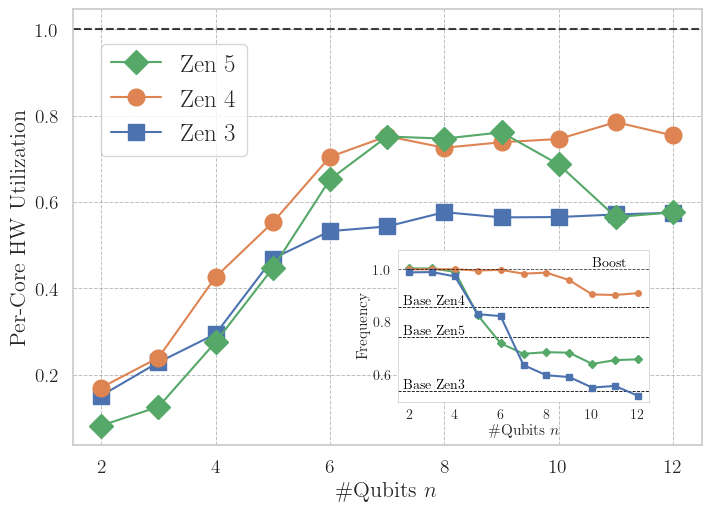

In [19]:
# throughput

outdir = f"{predir}/plots"
outfile = f"{outdir}/throughput"

splits = [8, 11, 12]

archs = [3, 4, 5] # zen3, zen4, zen5
names = {3: "vsc", 4 : "hpcgpu2", 5 : "hpcgpu3"}
hardwares = {3: "7713", 4 : "9354P", 5 : "9255"}

##################################################################

datas = {}

for arch in archs:
    datas[arch] = []
    for split in splits:
        datas[arch].append(get_data(f"{predir}/mm/{names[arch]}/simd/{split}", outdir, "werner", hardwares[arch], "running"))

##################################################################


qubits = []
for data in datas[3]:
    qubits = qubits + list(data["qubits"])
qubits = np.array(qubits)

utils = {}
freqs = {}
base_freq = {}

for arch in archs:
    utils[arch] = []
    for data in datas[arch]:
        print(arch, compute_PP_vs_n(data)/1e6)
        print("achieved", data["AP"]/1e6, "\n")
        utils[arch] = utils[arch] + list(data["AP"]/compute_PP_vs_n(data))
    utils[arch] = np.array(utils[arch])

for arch in archs:
    freqs[arch] = []
    for data in datas[arch]:
        freqs[arch] = freqs[arch] + list(data["freq"]/data["HW"]["max_freq"])
        base_freq[arch] = data["HW"]["freq"]/data["HW"]["max_freq"]
    freqs[arch] = np.array(freqs[arch])
    base_freq[arch] = np.array(base_freq[arch])


##################################################################

fg, ax = plt.subplots(layout="constrained", figsize=(7, 5))

colors = []
for i in range(10):
    colors.append(ax._get_lines.get_next_color())

ax.plot(qubits, utils[3], marker="s", label="Zen 3", c=colors[0], markersize=12)
ax.plot(qubits, utils[4], marker="o", label="Zen 4", c=colors[1], markersize=12)
ax.plot(qubits, utils[5], marker="D", label="Zen 5", c=colors[2], markersize=12)

# ax.plot(qubits, data_zen3["freq"]/data_zen3["HW"]["max_freq"], marker="v", label="Zen3 freq")
# ax.plot(qubits_45, data_zen4["freq"]/data_zen4["HW"]["max_freq"], marker="v", label="Zen4 freq")
# ax.plot(qubits, data_zen5["freq"]/data_zen5["HW"]["max_freq"], marker="v", label="Zen5 freq")

ax.axhline(y=1, linestyle="--", c="black", alpha=0.75)


handles, labels = ax.get_legend_handles_labels()
handles = [handles[2], handles[1], handles[0]]
labels = [labels[2], labels[1], labels[0]]
ax.legend(handles, labels, ncol=1, fontsize=18, markerscale=1.0, handlelength=2.0, loc="upper left", bbox_to_anchor=(0.025, 0.95))
ax.set_xlabel("\#Qubits $n$")
ax.set_ylabel("Per-Core HW Utilization")
ax.grid(which="major", linestyle="--", linewidth=0.7, color="gray", alpha=0.5)
ax.grid(which="minor", visible=False)



ax_inset = inset_axes(
    ax,
    width="40%",
    height="35%",
    loc="lower right",
    bbox_to_anchor=(-0.07, 0.08, 1, 1),  # increased x from 0.08 to 0.15
    bbox_transform=ax.transAxes,
)

# Scale factor: inset is ~30% linear size of main axes,
# so fonts/markers/lines should shrink roughly proportionally
inset_fontsize = 10
inset_markersize = 4
inset_linewidth = 0.6

ax_inset.axhline(y=base_freq[5], linestyle="--", linewidth=inset_linewidth, color="black")
ax_inset.axhline(y=base_freq[4], linestyle="--", linewidth=inset_linewidth, color="black")
ax_inset.axhline(y=base_freq[3], linestyle="--", linewidth=inset_linewidth, color="black")

ax_inset.plot(qubits, freqs[5], marker="D", label="Zen 5", c=colors[2], markersize=inset_markersize)
ax_inset.plot(qubits, freqs[4], marker="o", label="Zen 4", c=colors[1], markersize=inset_markersize)
ax_inset.plot(qubits, freqs[3], marker="s", label="Zen 3", c=colors[0], markersize=inset_markersize)

ax_inset.axhline(y=1, linestyle="--", c="black", alpha=0.75, linewidth=inset_linewidth)

ax_inset.set_xlabel("\\#Qubits $n$", fontsize=11, labelpad=2)
ax_inset.set_ylabel("Frequency", fontsize=11, labelpad=2)
ax_inset.tick_params(axis="both", labelsize=10, pad=-1)

ax_inset.grid(which="major", linestyle="--", linewidth=0.5, color="gray", alpha=0.5)
ax_inset.grid(which="minor", visible=False)

ax_inset.text(1.75, base_freq[4] * 1.01, "Base Zen4", color="black", fontsize=inset_fontsize, fontweight="bold")
ax_inset.text(1.75, base_freq[5] * 1.01, "Base Zen5", color="black", fontsize=inset_fontsize, fontweight="bold")
ax_inset.text(1.75, base_freq[3] * 1.01, "Base Zen3", color="black", fontsize=inset_fontsize, fontweight="bold")
ax_inset.text(10, 1.01, "Boost", color="black", fontsize=inset_fontsize, fontweight="bold")

ax_inset.set_ylim(None, 1.075)

for spine in ax_inset.spines.values():
    spine.set_linewidth(0.5)


ax_inset.grid(False)



for arch in archs:
    for data in datas[arch]:
        print(f"{names[arch]}, qubits = {data['qubits']}:  num_meas =  {data['num_meas']}, order = {data['orders'][-1]}, num_runs = {data['num_runs']}")

if store_plots:
    # fg.savefig(f"{outfile}.png")
    fg.savefig(f"{outfile}.pdf", bbox_inches="tight")
plt.show()

In [20]:
utils

{3: array([0.15116112, 0.22831861, 0.29401759, 0.46859011, 0.53216856,
        0.54308259, 0.5760787 , 0.56398863, 0.56482246, 0.57079029,
        0.57475212]),
 4: array([0.16982443, 0.23915885, 0.42594295, 0.55245103, 0.70422712,
        0.75210022, 0.72527589, 0.73810122, 0.74551587, 0.78462417,
        0.75368092]),
 5: array([0.08189638, 0.12523357, 0.27524324, 0.44656461, 0.652033  ,
        0.75133961, 0.74650363, 0.76099862, 0.68661222, 0.56464593,
        0.57595754])}